# Neural Network Weight Optimisation in Low-Dimensional Subspaces

## Imports

In [129]:
import torch

from torch.utils.data import DataLoader

from torchsummary import summary

### Import utils

In [506]:
%load_ext autoreload
%autoreload 2

from utils.show_dataloader_imgs import *
from utils.show_inference import *

from utils.mnist_dataloader import *

from utils.train_model import *

from utils.fitness_function import *
from utils.ga_utils import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Import models

In [167]:
%load_ext autoreload
%autoreload 2

from models.mnist_mlp import *
from models.lenet5 import *
from models.vector_mlp import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Import optimizers

In [441]:
%load_ext autoreload
%autoreload 2

from optimizers.pso import *
from optimizers.ga import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Global constants

In [ ]:
DEVICE = "cuda:0"
BATCH_SIZE = 1024*4
CHUNK_SIZE = 64

## Create DataLoaders

### MNIST

In [254]:
mnist_train_dataset = MNISTDataset('data/mnist/mnist_train.csv')
mnist_test_dataset = MNISTDataset('data/mnist/mnist_test.csv')

In [ ]:
mnist_train_dataloader = DataLoader(mnist_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
mnist_test_dataloader = DataLoader(mnist_test_dataset, batch_size=BATCH_SIZE, shuffle=True)

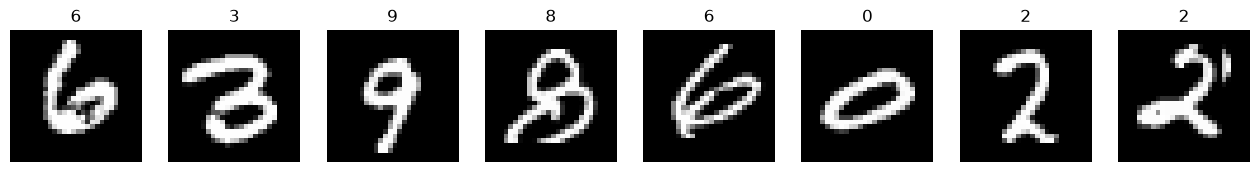

In [256]:
show_dataloader_imgs(mnist_train_dataloader)

### Fashion-MNIST

In [50]:
fashion_mnist_train_dataset = MNISTDataset('data/fashionmnist/fashion-mnist_train.csv')
fashion_mnist_test_dataset = MNISTDataset('data/fashionmnist/fashion-mnist_test.csv')

In [ ]:
fashion_mnist_train_dataloader = DataLoader(fashion_mnist_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
fashion_mnist_test_dataloader = DataLoader(fashion_mnist_test_dataset, batch_size=BATCH_SIZE, shuffle=True)

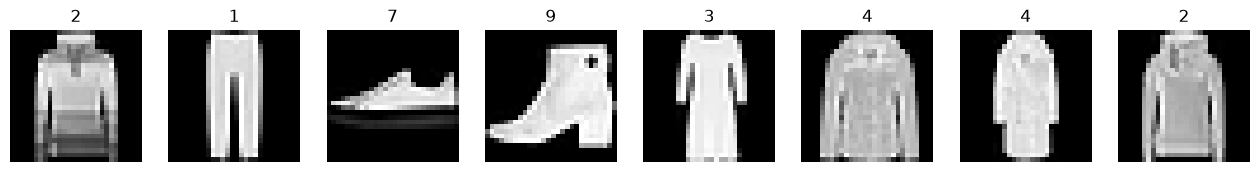

In [56]:
show_dataloader_imgs(fashion_mnist_train_dataloader)

## Train MLP in higher dimension

### Create model

In [526]:
model = MNIST_MLP([200, 200]).to(DEVICE)
summary(model, (BATCH_SIZE, 784))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1            [-1, 8192, 200]         157,000
              ReLU-2            [-1, 8192, 200]               0
            Linear-3            [-1, 8192, 200]          40,200
              ReLU-4            [-1, 8192, 200]               0
            Linear-5             [-1, 8192, 10]           2,010
Total params: 199,210
Trainable params: 199,210
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 24.50
Forward/backward pass size (MB): 50.62
Params size (MB): 0.76
Estimated Total Size (MB): 75.88
----------------------------------------------------------------


### Set training hyperparameters

In [527]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

### Training

In [528]:
model, train_losses, train_accs, val_losses, val_accs = train_model(
    model, DEVICE,
    mnist_train_dataloader, mnist_test_dataloader,
    criterion, optimizer, scheduler,
    epochs=50, patience=10
)
torch.save(model.state_dict(), 'out/mlp_weights.pth')

Epoch [1/50]  Train Loss: 2.1472  Train Acc: 0.5319  |  Val Loss: 1.7822  Val Acc: 0.7318
Epoch [2/50]  Train Loss: 1.4461  Train Acc: 0.7671  |  Val Loss: 0.9283  Val Acc: 0.8249
Epoch [3/50]  Train Loss: 0.7351  Train Acc: 0.8295  |  Val Loss: 0.5124  Val Acc: 0.8614
Epoch [4/50]  Train Loss: 0.4676  Train Acc: 0.8659  |  Val Loss: 0.3905  Val Acc: 0.8900
Epoch [5/50]  Train Loss: 0.3784  Train Acc: 0.8894  |  Val Loss: 0.3370  Val Acc: 0.9047
Epoch [6/50]  Train Loss: 0.3352  Train Acc: 0.9023  |  Val Loss: 0.3102  Val Acc: 0.9097
Epoch [7/50]  Train Loss: 0.3065  Train Acc: 0.9115  |  Val Loss: 0.2865  Val Acc: 0.9162
Epoch [8/50]  Train Loss: 0.2845  Train Acc: 0.9189  |  Val Loss: 0.2681  Val Acc: 0.9225
Epoch [9/50]  Train Loss: 0.2673  Train Acc: 0.9239  |  Val Loss: 0.2587  Val Acc: 0.9255
Epoch [10/50]  Train Loss: 0.2561  Train Acc: 0.9271  |  Val Loss: 0.2459  Val Acc: 0.9291
Epoch [11/50]  Train Loss: 0.2441  Train Acc: 0.9317  |  Val Loss: 0.2347  Val Acc: 0.9310
Epoch [1

### Inference

In [ ]:
show_inference(model, mnist_test_dataloader, DEVICE)

## Train CNN in higher dimension

### Create model

In [522]:
model = LeNet5().to(DEVICE)
summary(model, (BATCH_SIZE, 784))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 28, 28]             156
           Sigmoid-2            [-1, 6, 28, 28]               0
         AvgPool2d-3            [-1, 6, 14, 14]               0
            Conv2d-4           [-1, 16, 10, 10]           2,416
           Sigmoid-5           [-1, 16, 10, 10]               0
         AvgPool2d-6             [-1, 16, 5, 5]               0
           Flatten-7                  [-1, 400]               0
            Linear-8                  [-1, 120]          48,120
           Sigmoid-9                  [-1, 120]               0
           Linear-10                   [-1, 84]          10,164
          Sigmoid-11                   [-1, 84]               0
           Linear-12                   [-1, 10]             850
Total params: 61,706
Trainable params: 61,706
Non-trainable params: 0
---------------------------------

### Set training hyperparameters

In [523]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

### Training

In [524]:
model, train_losses, train_accs, val_losses, val_accs = train_model(
    model, DEVICE,
    mnist_train_dataloader, mnist_test_dataloader,
    criterion, optimizer, scheduler,
    epochs=50, patience=10
)
torch.save(model.state_dict(), 'out/lenet_weights.pth')

Epoch [1/50]  Train Loss: 2.3079  Train Acc: 0.1031  |  Val Loss: 2.3051  Val Acc: 0.0982
Epoch [2/50]  Train Loss: 2.3039  Train Acc: 0.1019  |  Val Loss: 2.3010  Val Acc: 0.1135
Epoch [3/50]  Train Loss: 2.3016  Train Acc: 0.1124  |  Val Loss: 2.3015  Val Acc: 0.1135
Epoch [4/50]  Train Loss: 2.3014  Train Acc: 0.1124  |  Val Loss: 2.3010  Val Acc: 0.1135
Epoch [5/50]  Train Loss: 2.3010  Train Acc: 0.1124  |  Val Loss: 2.3003  Val Acc: 0.1135
Epoch [6/50]  Train Loss: 2.3004  Train Acc: 0.1124  |  Val Loss: 2.2994  Val Acc: 0.1135
Epoch [7/50]  Train Loss: 2.2989  Train Acc: 0.1124  |  Val Loss: 2.2967  Val Acc: 0.1135
Epoch [8/50]  Train Loss: 2.2947  Train Acc: 0.1127  |  Val Loss: 2.2886  Val Acc: 0.1177
Epoch [9/50]  Train Loss: 2.2811  Train Acc: 0.1532  |  Val Loss: 2.2631  Val Acc: 0.2112
Epoch [10/50]  Train Loss: 2.2411  Train Acc: 0.2132  |  Val Loss: 2.1934  Val Acc: 0.2514
Epoch [11/50]  Train Loss: 2.1493  Train Acc: 0.2893  |  Val Loss: 2.0702  Val Acc: 0.3165
Epoch [1

In [158]:
list(model.parameters())[0]

Parameter containing:
tensor([[[[-6.6990e-01, -3.8111e-01, -3.4228e-01,  5.0464e-02, -2.0915e-01],
          [-6.6422e-04,  9.0155e-01,  1.3795e+00,  1.1099e+00,  1.7925e-01],
          [-1.5880e-01,  1.0456e+00,  1.8029e+00,  1.1567e+00,  3.2204e-01],
          [-2.3078e-01,  2.9678e-01,  6.1402e-01,  3.6121e-01, -4.0558e-01],
          [-8.1593e-01, -3.5816e-01, -5.5610e-01, -1.0546e+00, -1.0395e+00]]],


        [[[ 3.7775e-01, -5.4046e-02, -4.5066e-01, -9.3929e-01,  9.0695e-02],
          [ 3.4373e-02, -6.9494e-01, -1.6908e+00, -8.6632e-01, -2.2081e-02],
          [-1.7100e-01, -1.3483e+00, -1.7667e+00, -2.5256e-01,  4.6301e-01],
          [-3.4600e-01, -1.9469e+00, -8.8601e-01,  2.5574e-01,  5.0143e-01],
          [-7.9731e-01, -1.5543e+00, -3.7540e-01,  5.5464e-01,  1.0042e+00]]],


        [[[-8.5353e-01, -6.5270e-01, -7.2436e-01, -3.3313e-01, -4.3668e-01],
          [-6.0149e-01,  7.4307e-01,  1.1028e+00,  1.3222e+00,  4.3542e-01],
          [-3.6680e-01,  1.0783e+00,  2.2329e+

### Inference

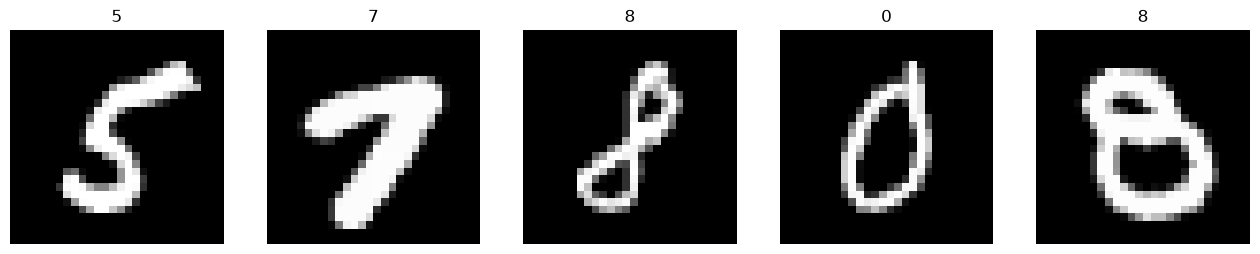

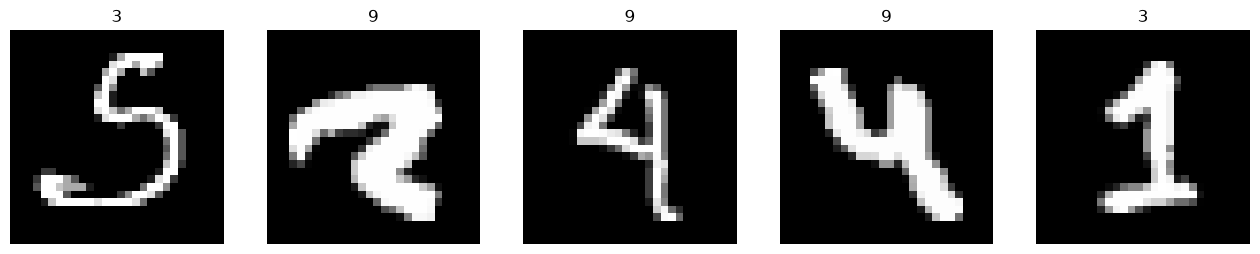

In [525]:
show_inference(model, mnist_test_dataloader, DEVICE)

## Train MLP in lower dimension

### Create model

In [531]:
model = VectorMLP(MNIST_MLP([200, 200]), lower_dim=1000).to(DEVICE)
summary(model, (BATCH_SIZE, 784))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1            [-1, 8192, 200]         157,000
              ReLU-2            [-1, 8192, 200]               0
            Linear-3            [-1, 8192, 200]          40,200
              ReLU-4            [-1, 8192, 200]               0
            Linear-5             [-1, 8192, 10]           2,010
         MNIST_MLP-6             [-1, 8192, 10]               0
Total params: 199,210
Trainable params: 199,210
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 24.50
Forward/backward pass size (MB): 51.25
Params size (MB): 0.76
Estimated Total Size (MB): 76.51
----------------------------------------------------------------


### Set training hyperparameters

In [436]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

### Training

In [ ]:
model, train_losses, train_accs, val_losses, val_accs = train_model(
    model, DEVICE,
    mnist_train_dataloader, mnist_test_dataloader,
    criterion, optimizer, scheduler,
    epochs=50, patience=10
)
torch.save(model.state_dict(), 'out/lower_mlp_weights.pth')

Epoch [1/50]  Train Loss: 1.8075  Train Acc: 0.4105  |  Val Loss: 0.8155  Val Acc: 0.7393
Epoch [2/50]  Train Loss: 0.7309  Train Acc: 0.7823  |  Val Loss: 0.5700  Val Acc: 0.8378
Epoch [3/50]  Train Loss: 0.5190  Train Acc: 0.8464  |  Val Loss: 0.4356  Val Acc: 0.8660
Epoch [4/50]  Train Loss: 0.4316  Train Acc: 0.8686  |  Val Loss: 0.3965  Val Acc: 0.8814
Epoch [5/50]  Train Loss: 0.3839  Train Acc: 0.8846  |  Val Loss: 0.3658  Val Acc: 0.8884
Epoch [6/50]  Train Loss: 0.3579  Train Acc: 0.8923  |  Val Loss: 0.3547  Val Acc: 0.8897
Epoch [7/50]  Train Loss: 0.3384  Train Acc: 0.8989  |  Val Loss: 0.3300  Val Acc: 0.8989
Epoch [8/50]  Train Loss: 0.3231  Train Acc: 0.9021  |  Val Loss: 0.3320  Val Acc: 0.8981
Epoch [9/50]  Train Loss: 0.3179  Train Acc: 0.9045  |  Val Loss: 0.3286  Val Acc: 0.9003
Epoch [10/50]  Train Loss: 0.3060  Train Acc: 0.9072  |  Val Loss: 0.3201  Val Acc: 0.8990
Epoch [11/50]  Train Loss: 0.3003  Train Acc: 0.9098  |  Val Loss: 0.3105  Val Acc: 0.9051
Epoch [1

### Inference

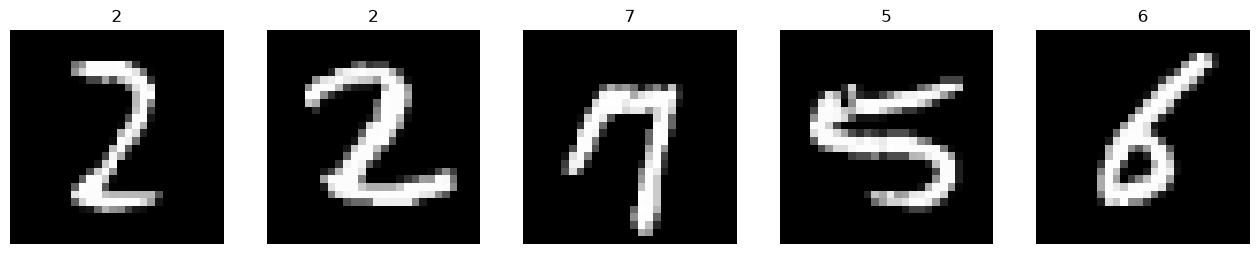

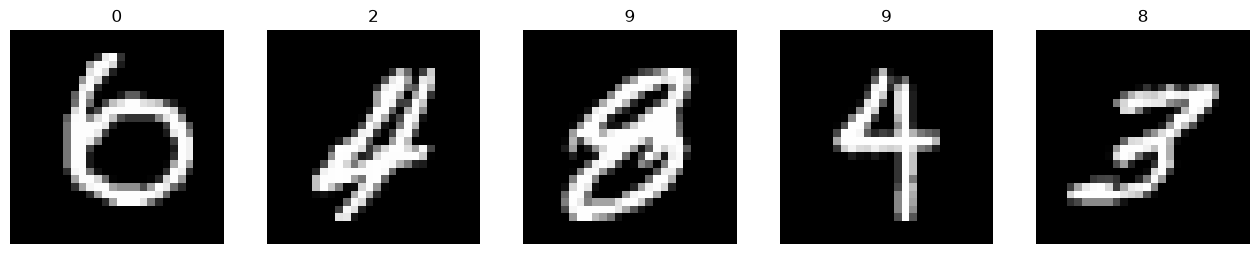

In [ ]:
show_inference(model, mnist_test_dataloader, DEVICE)

## Train CNN in lower dimension

### Create model

In [513]:
model = VectorMLP(LeNet5(), lower_dim=1000).to(DEVICE)
summary(model, (BATCH_SIZE, 784))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 28, 28]             156
           Sigmoid-2            [-1, 6, 28, 28]               0
         AvgPool2d-3            [-1, 6, 14, 14]               0
            Conv2d-4           [-1, 16, 10, 10]           2,416
           Sigmoid-5           [-1, 16, 10, 10]               0
         AvgPool2d-6             [-1, 16, 5, 5]               0
           Flatten-7                  [-1, 400]               0
            Linear-8                  [-1, 120]          48,120
           Sigmoid-9                  [-1, 120]               0
           Linear-10                   [-1, 84]          10,164
          Sigmoid-11                   [-1, 84]               0
           Linear-12                   [-1, 10]             850
           LeNet5-13                   [-1, 10]               0
Total params: 61,706
Trainable params: 

### Set training hyperparameters

In [514]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

### Training

In [515]:
model, train_losses, train_accs, val_losses, val_accs = train_model(
    model, DEVICE,
    mnist_train_dataloader, mnist_test_dataloader,
    criterion, optimizer, scheduler,
    epochs=50, patience=10
)
torch.save(model.state_dict(), 'out/lower_cnn_weights.pth')

Epoch [1/50]  Train Loss: 2.5188  Train Acc: 0.0986  |  Val Loss: 2.3186  Val Acc: 0.1010
Epoch [2/50]  Train Loss: 2.3440  Train Acc: 0.1069  |  Val Loss: 2.3055  Val Acc: 0.1009
Epoch [3/50]  Train Loss: 2.3108  Train Acc: 0.0959  |  Val Loss: 2.3107  Val Acc: 0.0892
Epoch [4/50]  Train Loss: 2.3046  Train Acc: 0.1027  |  Val Loss: 2.3040  Val Acc: 0.1135
Epoch [5/50]  Train Loss: 2.3036  Train Acc: 0.1124  |  Val Loss: 2.3010  Val Acc: 0.1135
Epoch [6/50]  Train Loss: 2.3011  Train Acc: 0.1124  |  Val Loss: 2.3011  Val Acc: 0.1135
Epoch [7/50]  Train Loss: 2.3010  Train Acc: 0.1124  |  Val Loss: 2.3003  Val Acc: 0.1135
Epoch [8/50]  Train Loss: 2.3004  Train Acc: 0.1124  |  Val Loss: 2.2997  Val Acc: 0.1135
Epoch [9/50]  Train Loss: 2.2996  Train Acc: 0.1124  |  Val Loss: 2.2989  Val Acc: 0.1135
Epoch [10/50]  Train Loss: 2.2985  Train Acc: 0.1124  |  Val Loss: 2.2967  Val Acc: 0.1135
Epoch [11/50]  Train Loss: 2.2959  Train Acc: 0.1124  |  Val Loss: 2.2924  Val Acc: 0.1135
Epoch [1

### Inference

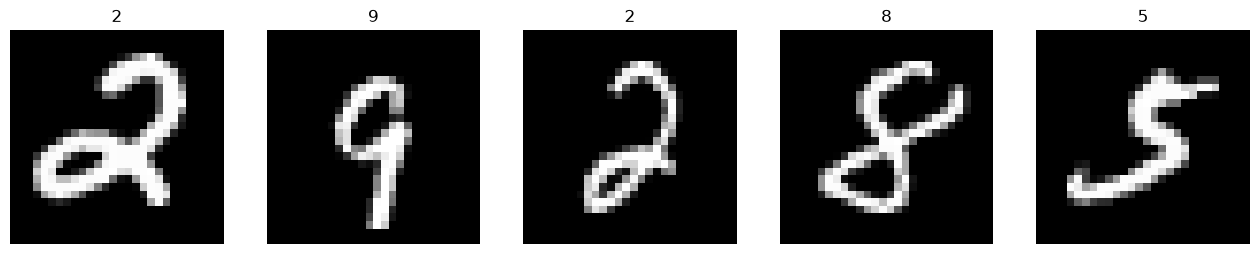

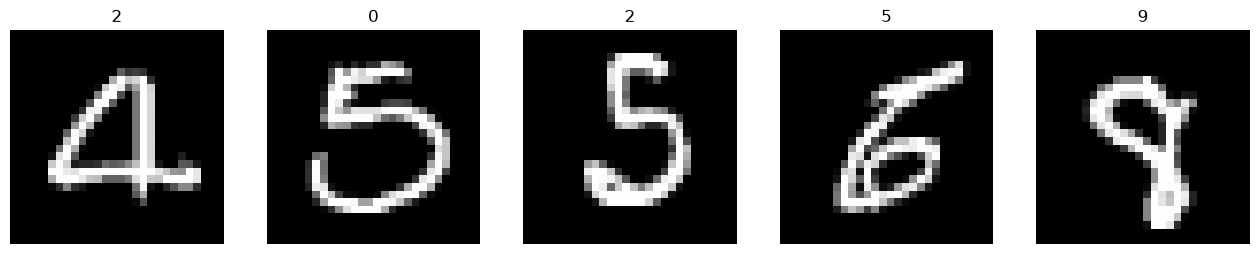

In [516]:
show_inference(model, mnist_test_dataloader, DEVICE)

## Particle Swarm Optimization

### Create optimizer

In [ ]:
fitness_fn = FitnessFunction(model, mnist_train_dataloader, CHUNK_SIZE, DEVICE)
optimizer = ParticleSwarmOptimizer(1024*4, model.lower_dim, fitness_fn, DEVICE)

### Training

In [440]:
best_weights, fitness_history = optimizer.train(max_iter=100, patience=15)

Iteration [1/100]    Best fitness: 0.2035
Iteration [2/100]    Best fitness: 0.2323
Iteration [3/100]    Best fitness: 0.2360
Iteration [4/100]    Best fitness: 0.2465
Iteration [5/100]    Best fitness: 0.2659
Iteration [6/100]    Best fitness: 0.2931
Iteration [7/100]    Best fitness: 0.3030
Iteration [8/100]    Best fitness: 0.3294
Iteration [9/100]    Best fitness: 0.3294
Iteration [10/100]    Best fitness: 0.3385
Iteration [11/100]    Best fitness: 0.3748
Iteration [12/100]    Best fitness: 0.3748
Iteration [13/100]    Best fitness: 0.3791
Iteration [14/100]    Best fitness: 0.3976
Iteration [15/100]    Best fitness: 0.4022
Iteration [16/100]    Best fitness: 0.4109
Iteration [17/100]    Best fitness: 0.4130
Iteration [18/100]    Best fitness: 0.4130
Iteration [19/100]    Best fitness: 0.4239
Iteration [20/100]    Best fitness: 0.4277
Iteration [21/100]    Best fitness: 0.4277
Iteration [22/100]    Best fitness: 0.4277
Iteration [23/100]    Best fitness: 0.4277
Iteration [24/100]  

### Inference

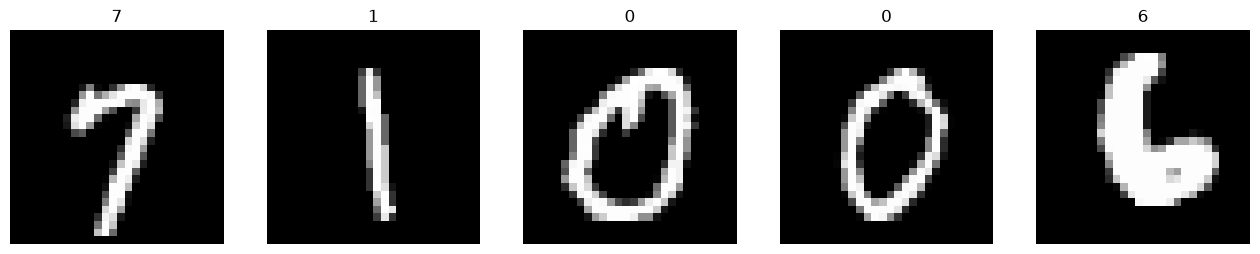

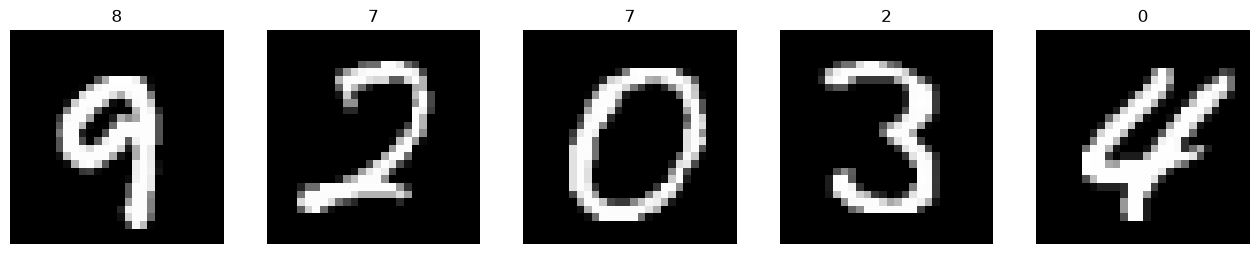

In [ ]:
with torch.no_grad():
    model.lower_weights[:] = best_weights.to(DEVICE)
show_inference(model, mnist_test_dataloader, DEVICE)

## Genetic Algorithm

### Create optimizer

In [541]:
fitness_fn = FitnessFunction(model, mnist_train_dataloader, CHUNK_SIZE, DEVICE)
optimizer = GeneticAlgorithmOptimizer(1024, model.lower_dim, fitness_fn, DEVICE)

### Training

In [542]:
selection_fn = lambda *argv: tournament_selection(*argv, group_size=5, device=DEVICE)
crossover_fn = lambda *argv: arithmetic_crossover(*argv, device=DEVICE)
mutation_fn = lambda *argv: gaussian_mutation(*argv, device=DEVICE)

best_weights, fitness_history = optimizer.train(selection_fn, crossover_fn, mutation_fn, max_iter=100, patience=15)

Iteration [1/100]    Best fitness: 0.1889
Iteration [2/100]    Best fitness: 0.2042
Iteration [3/100]    Best fitness: 0.2442
Iteration [4/100]    Best fitness: 0.2442
Iteration [5/100]    Best fitness: 0.2620
Iteration [6/100]    Best fitness: 0.2620
Iteration [7/100]    Best fitness: 0.2620
Iteration [8/100]    Best fitness: 0.2620
Iteration [9/100]    Best fitness: 0.2620
Iteration [10/100]    Best fitness: 0.2620
Iteration [11/100]    Best fitness: 0.2620
Iteration [12/100]    Best fitness: 0.2643


KeyboardInterrupt: 

### Inference

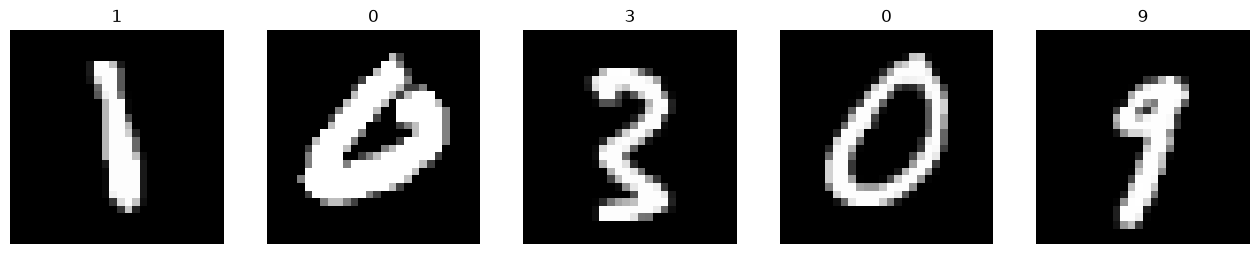

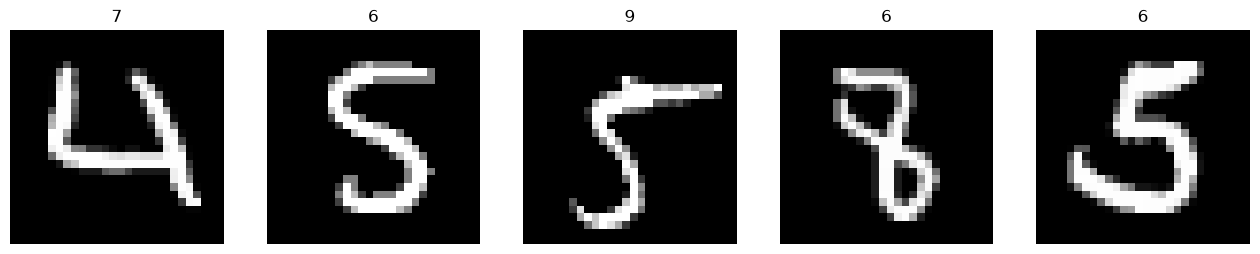

In [512]:
with torch.no_grad():
    model.lower_weights[:] = best_weights.to(DEVICE)
show_inference(model, mnist_test_dataloader, DEVICE)